# How does a schedule delay change campus encounters?

On a fictional campus, two people follow synthetic morning, midday, and afternoon itineraries. We estimate the chance they share at least one modeled location during a day, then replay each day with Person B delayed by 5, 10, or 15 minutes.

## Campus and time rules

The five places form a small graph. The numbers are walking times in minutes.

```text
East Gate --3-- Library --4-- Café --3-- Studio --4-- West Gate
```

- A simulated day runs from midnight to midnight. Each array slot represents a one-minute interval, so 09:00 means [09:00, 09:01). An encounter requires both people to occupy the same campus node during at least one slot. Leaving at 09:01 and arriving at 09:01 gives no overlap.
- Routes are fixed paths through the graph. Walking takes the listed time, and walking minutes are excluded from the encounter definition. Passing through a node without dwelling adds no occupied minute.
- Between outings both people are off campus and cannot meet in the model. All times are synthetic. We sample start times and dwell durations independently, with fixed walking times and no response to encounters.

In [1]:
import numpy as np
from IPython.display import Markdown, display

MINUTES_PER_DAY = 24 * 60
OFF_NODE = -1
PLACES = ["East Gate", "Library", "Café", "Studio", "West Gate"]
PLACE_ID = {place: index for index, place in enumerate(PLACES)}

WALK_MINUTES = {
    frozenset(("East Gate", "Library")): 3,
    frozenset(("Library", "Café")): 4,
    frozenset(("Café", "Studio")): 3,
    frozenset(("Studio", "West Gate")): 4,
}


def add_outing(day, start, route, dwell_minutes):
    """Record each stop and advance the clock by each walk."""
    minute = start
    for index, (place, dwell) in enumerate(zip(route, dwell_minutes)):
        end = minute + dwell
        first, last = max(0, minute), min(len(day), end)
        if first < last:
            day[first:last] = PLACE_ID[place]
        minute = end
        if index + 1 < len(route):
            edge = frozenset((place, route[index + 1]))
            minute += WALK_MINUTES[edge]


def encounter_minutes(day_a, day_b, delay=0):
    """Return A's clock minutes with shared node occupancy after delaying B."""
    # B's original minute t becomes minute t + delay, without wrapping.
    first = max(0, delay)
    last = min(len(day_a), len(day_b) + delay)
    if first >= last:
        return np.array([], dtype=int)
    a = day_a[first:last]
    b = day_b[first - delay:last - delay]
    shared = (a == b) & (a != OFF_NODE)
    return np.flatnonzero(shared) + first

## A day you can check by hand

A leaves East Gate at 09:00, walks for 3 minutes, and occupies the Library from 09:03 up to 09:08. B spends two minutes at the Library starting at 09:06. They overlap in the 09:06 and 09:07 slots. Delaying B by 2 minutes makes B arrive exactly when A leaves, so there is no encounter.

In [2]:
example_a = np.full(MINUTES_PER_DAY, OFF_NODE, dtype=np.int8)
example_b = np.full_like(example_a, OFF_NODE)
add_outing(example_a, 9 * 60, ["East Gate", "Library"], [0, 5])
add_outing(example_b, 9 * 60 + 6, ["Library"], [2])

assert encounter_minutes(example_a, example_b).tolist() == [546, 547]
assert encounter_minutes(example_a, example_b, delay=2).size == 0
print("Hand check passed: two shared minutes at baseline and zero after a 2-minute delay.")
# Starting B five minutes earlier puts B's visit before A's arrival.
assert encounter_minutes(example_a, example_b, delay=-5).size == 0
# Starting B one minute earlier shifts their shared slots to 09:05 and 09:06.
assert encounter_minutes(example_a, example_b, delay=-1).tolist() == [545, 546]


Hand check passed: two shared minutes at baseline and zero after a 2-minute delay.


## Generate and replay synthetic days

Each itinerary row gives a planned start, a route, and inclusive dwell ranges in route order. Actual starts vary uniformly by up to 8 minutes in either direction. A zero dwell means the person starts walking immediately or leaves campus on arrival at an exit. The outings are far enough apart that even the longest sampled outing finishes before the next one starts.

A trial samples one full day for both people, then checks all four delays on that same pair of timelines. A day with several shared minutes or several encounters still counts as one success. Reusing the day lets us compare the delays without changing the underlying schedule draws.

In [3]:
# (planned start in minutes after midnight, route, dwell ranges in minutes)
ITINERARY_A = [
    (9 * 60, ("East Gate", "Library", "Café"), ((0, 0), (12, 20), (4, 8))),
    (12 * 60, ("Studio", "Café", "Library"), ((0, 0), (10, 18), (5, 10))),
    (15 * 60, ("Library", "Café", "Studio"), ((7, 13), (0, 0), (8, 14))),
]
ITINERARY_B = [
    (8 * 60 + 48, ("West Gate", "Studio", "Café", "Library"), ((0, 0), (3, 7), (0, 0), (8, 14))),
    (12 * 60 + 4, ("Library", "Café", "Studio"), ((0, 0), (7, 13), (4, 8))),
    (14 * 60 + 43, ("West Gate", "Studio", "Café"), ((0, 0), (8, 14), (5, 9))),
]


def simulate_day(itinerary, rng):
    day = np.full(MINUTES_PER_DAY, OFF_NODE, dtype=np.int8)
    for planned_start, route, dwell_ranges in itinerary:
        start = planned_start + rng.integers(-8, 9)
        dwells = [rng.integers(low, high + 1) for low, high in dwell_ranges]
        add_outing(day, start, route, dwells)
    return day


DELAYS = [0, 5, 10, 15]
TRIALS = 20_000
rng = np.random.default_rng(2026)
encountered = np.zeros((TRIALS, len(DELAYS)), dtype=bool)

# Period boundaries are 12:00 and 14:00 on the shifted clock.
PERIODS = ["Morning (before 12:00)", "Midday (12:00–13:59)", "Afternoon/evening (14:00 onward)"]
PERIOD_STARTS = [12 * 60, 14 * 60]
# Each trial can have encounters in several period/location pairs.
by_place_and_period = np.zeros(
    (TRIALS, len(DELAYS), len(PERIODS), len(PLACES)), dtype=bool
)
first_period = np.full((TRIALS, len(DELAYS)), -1, dtype=int)
first_place = np.full_like(first_period, -1)

shared_minute_counts = np.zeros_like(encountered, dtype=int)

SWEEP_SHIFTS = np.arange(-30, 31)
# Each series counts days with any overlap in its selected place and window.
SWEEP_SERIES = [
    ("Morning Library", "Library", 0, 12 * 60),
    ("Midday Café", "Café", 12 * 60, 14 * 60),
    ("Afternoon Studio", "Studio", 14 * 60, MINUTES_PER_DAY),
]
sweep_counts = np.zeros((1 + len(SWEEP_SERIES), len(SWEEP_SHIFTS)), dtype=int)

for trial in range(TRIALS):
    day_a = simulate_day(ITINERARY_A, rng)
    day_b = simulate_day(ITINERARY_B, rng)
    for column, delay in enumerate(DELAYS):
        shared_minutes = encounter_minutes(day_a, day_b, delay)
        shared_minute_counts[trial, column] = shared_minutes.size
        encountered[trial, column] = shared_minutes.size > 0
        if shared_minutes.size:
            places = day_a[shared_minutes]
            periods = np.searchsorted(PERIOD_STARTS, shared_minutes, side="right")
            by_place_and_period[trial, column, periods, places] = True
            first_period[trial, column] = periods[0]
            first_place[trial, column] = places[0]
    for column, shift in enumerate(SWEEP_SHIFTS):
        shared_minutes = encounter_minutes(day_a, day_b, shift)
        sweep_counts[0, column] += shared_minutes.size > 0
        if shared_minutes.size:
            places = day_a[shared_minutes]
            for row, (_, place, first, last) in enumerate(SWEEP_SERIES, start=1):
                in_window = (shared_minutes >= first) & (shared_minutes < last)
                sweep_counts[row, column] += np.any(in_window & (places == PLACE_ID[place]))

original_columns = np.searchsorted(SWEEP_SHIFTS, DELAYS)
assert np.array_equal(sweep_counts[0, original_columns], encountered.sum(axis=0))
for row, (period, place) in enumerate(
    [(0, "Library"), (1, "Café"), (2, "Studio")], start=1
):
    expected = by_place_and_period[:, :, period, PLACE_ID[place]].sum(axis=0)
    assert np.array_equal(sweep_counts[row, original_columns], expected)


In [4]:
probability = encountered.mean(axis=0)
counts = encountered.sum(axis=0)
change_pp = 100 * (counts - counts[0]) / TRIALS

rows = [
    "| B delay (min) | Days with an encounter | Estimated probability | Change from baseline (pp) |",
    "| ---: | ---: | ---: | ---: |",
]
for delay, count, estimate, change in zip(
    DELAYS, encountered.sum(axis=0), probability, change_pp
):
    rows.append(f"| {delay} | {count:,} | {estimate:.2%} | {change:+.2f} |")
display(Markdown("\n".join(rows)))

| B delay (min) | Days with an encounter | Estimated probability | Change from baseline (pp) |
| ---: | ---: | ---: | ---: |
| 0 | 19,743 | 98.72% | +0.00 |
| 5 | 19,236 | 96.18% | -2.54 |
| 10 | 17,111 | 85.56% | -13.16 |
| 15 | 14,023 | 70.12% | -28.60 |

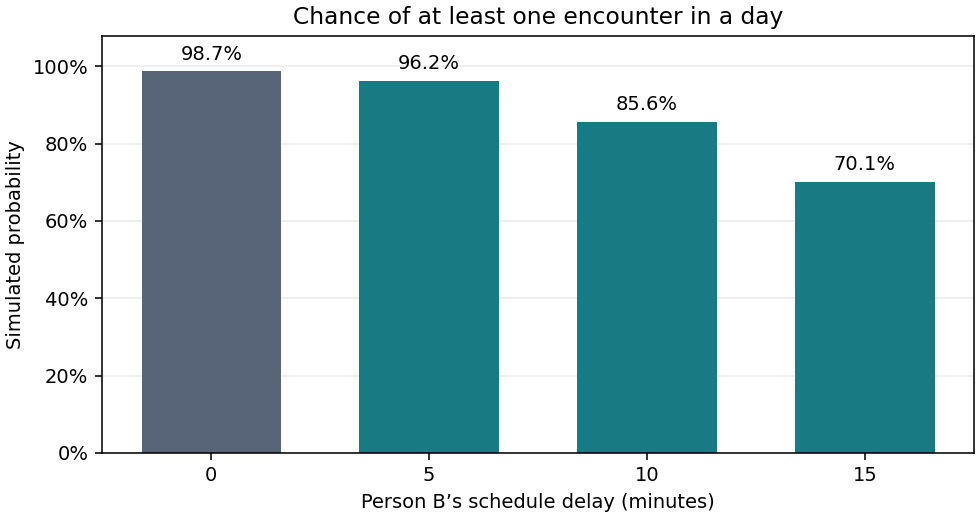

In [5]:
from io import BytesIO

from IPython.display import Image
from matplotlib.figure import Figure
from matplotlib.ticker import PercentFormatter

fig = Figure(figsize=(7, 3.7), layout="constrained")
ax = fig.subplots()
bars = ax.bar(DELAYS, probability, width=3.2, color=["#586579"] + ["#187a83"] * 3)
ax.bar_label(bars, labels=[f"{p:.1%}" for p in probability], padding=4)
ax.set(
    title="Chance of at least one encounter in a day",
    xlabel="Person B’s schedule delay (minutes)",
    ylabel="Simulated probability",
    xticks=DELAYS,
    ylim=(0, 1.08),
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
png = BytesIO()
fig.savefig(png, format="png", dpi=140)
display(Image(data=png.getvalue()))

In [6]:
best = int(np.argmax(probability))
display(Markdown(
    "## Interpretation\n\n"
    f"The baseline estimate is **{probability[0]:.2%}**. Across the four "
    f"settings, the highest estimate is **{probability[best]:.2%}** at a "
    f"**{DELAYS[best]}-minute delay** ({change_pp[best]:+.2f} percentage "
    f"points from baseline). At 15 minutes, the estimate is "
    f"**{probability[-1]:.2%}**. A delay can bring B’s earlier stops into "
    "overlap with A’s stops or move B’s later stops out of overlap. "
    "The pattern depends on the fictional itineraries, dwell ranges, and "
    "one-minute encounter rule. The percentages are Monte Carlo estimates."
))

## Interpretation

The baseline estimate is **98.72%**. Across the four settings, the highest estimate is **98.72%** at a **0-minute delay** (+0.00 percentage points from baseline). At 15 minutes, the estimate is **70.12%**. A delay can bring B’s earlier stops into overlap with A’s stops or move B’s later stops out of overlap. The pattern depends on the fictional itineraries, dwell ranges, and one-minute encounter rule. The percentages are Monte Carlo estimates.

## Where and when encounters happen

Each cell shows the percentage of all simulated days with at least one shared minute in that location and time window, followed by its percentage-point change from baseline. We classify each shared minute by its clock time after applying the delay. A day can appear in multiple rows, so adding row changes can double-count days.

In [7]:
assert np.array_equal(by_place_and_period.any(axis=(2, 3)), encountered)

rates = by_place_and_period.mean(axis=0)
rows = [
    "| Time of day | Location | 0 min | 5 min (change) | 10 min (change) | 15 min (change) |",
    "| --- | --- | ---: | ---: | ---: | ---: |",
]
for period, period_name in enumerate(PERIODS):
    for place, place_name in enumerate(PLACES):
        values = rates[:, period, place]
        cells = [f"{values[0]:.2%}"]
        cells.extend(f"{value:.2%} ({100 * (value - values[0]):+.2f} pp)" for value in values[1:])
        rows.append("| " + " | ".join([period_name, place_name, *cells]) + " |")
display(Markdown("\n".join(rows)))

| Time of day | Location | 0 min | 5 min (change) | 10 min (change) | 15 min (change) |
| --- | --- | ---: | ---: | ---: | ---: |
| Morning (before 12:00) | East Gate | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Morning (before 12:00) | Library | 91.31% | 88.20% (-3.11 pp) | 71.85% (-19.46 pp) | 47.70% (-43.61 pp) |
| Morning (before 12:00) | Café | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Morning (before 12:00) | Studio | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Morning (before 12:00) | West Gate | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Midday (12:00–13:59) | East Gate | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Midday (12:00–13:59) | Library | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Midday (12:00–13:59) | Café | 84.51% | 67.10% (-17.41 pp) | 42.10% (-42.41 pp) | 19.91% (-64.59 pp) |
| Midday (12:00–13:59) | Studio | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Midday (12:00–13:59) | West Gate | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Afternoon/evening (14:00 onward) | East Gate | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Afternoon/evening (14:00 onward) | Library | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Afternoon/evening (14:00 onward) | Café | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |
| Afternoon/evening (14:00 onward) | Studio | 0.07% | 2.33% (+2.26 pp) | 10.97% (+10.91 pp) | 28.32% (+28.26 pp) |
| Afternoon/evening (14:00 onward) | West Gate | 0.00% | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) | 0.00% (+0.00 pp) |

## Which changes drive the daily drop?

A **lost day** had an encounter at baseline and none at the tested delay. A **gained day** had none at baseline and an encounter at that delay. Days with encounters in both versions still count as successes, even if the place or time changes. To count each lost or gained day once, assign it to its first encounter in the version where it had one. A lost day may also have had later baseline encounters, so this attribution is an accounting convention.

The table reports lost and gained days as counts and the net contribution as percentage points out of all 20,000 days. The net contributions sum to the overall change for each delay, up to rounding.

In [8]:
rows = [
    "| Delay | First encounter window | Location | Lost days | Gained days | Net contribution (pp) |",
    "| ---: | --- | --- | ---: | ---: | ---: |",
]
highlights = []
for column, delay in enumerate(DELAYS[1:], start=1):
    lost = encountered[:, 0] & ~encountered[:, column]
    gained = ~encountered[:, 0] & encountered[:, column]
    net_count = 0
    biggest_loss = 0
    for period, period_name in enumerate(PERIODS):
        for place, place_name in enumerate(PLACES):
            lost_count = np.count_nonzero(
                lost & (first_period[:, 0] == period) & (first_place[:, 0] == place)
            )
            gained_count = np.count_nonzero(
                gained & (first_period[:, column] == period) & (first_place[:, column] == place)
            )
            if lost_count or gained_count:
                net = gained_count - lost_count
                net_count += net
                rows.append(
                    f"| {delay} min | {period_name} | {place_name} | "
                    f"{lost_count:,} | {gained_count:,} | {100 * net / TRIALS:+.2f} |"
                )
                if net < biggest_loss:
                    biggest_loss = net
                    biggest_loss_label = f"{period_name} at {place_name}"
    assert np.isclose(100 * net_count / TRIALS, change_pp[column])
    rows.append(
        f"| **{delay} min** | **All windows** | **All locations** | "
        f"**{lost.sum():,}** | **{gained.sum():,}** | **{change_pp[column]:+.2f}** |"
    )
    if biggest_loss < 0:
        highlights.append(
            f"- **{delay} min.** The largest negative contribution was "
            f"{biggest_loss_label} ({100 * biggest_loss / TRIALS:+.2f} pp)."
        )

display(Markdown("\n".join(rows)))
display(Markdown("\n".join(highlights)))

| Delay | First encounter window | Location | Lost days | Gained days | Net contribution (pp) |
| ---: | --- | --- | ---: | ---: | ---: |
| 5 min | Morning (before 12:00) | Library | 551 | 153 | -1.99 |
| 5 min | Midday (12:00–13:59) | Café | 117 | 8 | -0.55 |
| **5 min** | **All windows** | **All locations** | **668** | **161** | **-2.54** |
| 10 min | Morning (before 12:00) | Library | 2,628 | 168 | -12.30 |
| 10 min | Midday (12:00–13:59) | Café | 186 | 6 | -0.90 |
| 10 min | Afternoon/evening (14:00 onward) | Studio | 0 | 8 | +0.04 |
| **10 min** | **All windows** | **All locations** | **2,814** | **182** | **-13.16** |
| 15 min | Morning (before 12:00) | Library | 5,695 | 168 | -27.64 |
| 15 min | Midday (12:00–13:59) | Café | 220 | 6 | -1.07 |
| 15 min | Afternoon/evening (14:00 onward) | Studio | 0 | 21 | +0.10 |
| **15 min** | **All windows** | **All locations** | **5,915** | **195** | **-28.60** |

- **5 min.** The largest negative contribution was Morning (before 12:00) at Library (-1.99 pp).
- **10 min.** The largest negative contribution was Morning (before 12:00) at Library (-12.30 pp).
- **15 min.** The largest negative contribution was Morning (before 12:00) at Library (-27.64 pp).

## How much uncertainty comes from simulating 20,000 days?

Replaying each day under every delay is an example of *common random numbers*, a technique for comparing scenarios using matched simulation inputs. We subtract the baseline outcome (0 or 1) from the delayed outcome for each day, then average these differences. The Monte Carlo standard error is the sample standard deviation of the day-level differences divided by the square root of the number of days. An approximate 95% interval extends 1.96 standard errors in each direction.

These are pointwise intervals for the individual delays. They quantify simulation sampling error under the specified schedules and dwell distributions. Applying the results to a real campus would require evidence about how people move and how long they stay.

Reference: [Glasserman and Yao (1992), *Some Guidelines and Guarantees for Common Random Numbers*](https://business.columbia.edu/faculty/research/some-guidelines-and-guarantees-common-random-numbers).

In [9]:
paired_differences = encountered[:, 1:].astype(int) - encountered[:, [0]].astype(int)
paired_change_pp = 100 * paired_differences.sum(axis=0) / TRIALS
assert np.allclose(paired_change_pp, change_pp[1:])

standard_error_pp = 100 * paired_differences.std(axis=0, ddof=1) / np.sqrt(TRIALS)
rows = [
    "| Delay | Change from baseline (pp) | Approximate 95% Monte Carlo interval (pp) |",
    "| ---: | ---: | ---: |",
]
for delay, change, se in zip(DELAYS[1:], paired_change_pp, standard_error_pp):
    margin = 1.96 * se
    rows.append(f"| {delay} min | {change:+.2f} | [{change - margin:+.2f}, {change + margin:+.2f}] |")
display(Markdown("\n".join(rows)))

| Delay | Change from baseline (pp) | Approximate 95% Monte Carlo interval (pp) |
| ---: | ---: | ---: |
| 5 min | -2.54 | [-2.81, -2.26] |
| 10 min | -13.16 | [-13.66, -12.66] |
| 15 min | -28.60 | [-29.26, -27.94] |

## Does the pattern depend on what counts as an encounter?

The main analysis counts any shared minute. Here we reuse the same days to see what happens if we require at least 3 or 5 total shared minutes during the day. Those minutes can accumulate across separate stops or times. This tests sensitivity to the minimum amount of daily co-presence.

In [10]:
assert np.array_equal(shared_minute_counts >= 1, encountered)
thresholds = [1, 3, 5]
threshold_rates = np.array([
    (shared_minute_counts >= minutes).mean(axis=0) for minutes in thresholds
])
rows = [
    "| Minimum total shared minutes | " + " | ".join(f"{delay} min delay" for delay in DELAYS) + " |",
    "| ---: | ---: | ---: | ---: | ---: |",
]
for minutes, estimates in zip(thresholds, threshold_rates):
    rows.append(f"| {minutes} | " + " | ".join(f"{rate:.2%}" for rate in estimates) + " |")
display(Markdown("\n".join(rows)))

| Minimum total shared minutes | 0 min delay | 5 min delay | 10 min delay | 15 min delay |
| ---: | ---: | ---: | ---: | ---: |
| 1 | 98.72% | 96.18% | 85.56% | 70.12% |
| 3 | 96.72% | 92.47% | 77.38% | 58.50% |
| 5 | 93.22% | 87.13% | 67.93% | 46.73% |

## What happens across the full shift range?

We replay the same 20,000 days at every whole-minute shift from −30 to +30. Negative shifts start Person B earlier, and positive shifts start B later. Encounters use the shifted clock and stay within the modeled day. The overall line shows the chance of at least one encounter anywhere on campus. The three location lines show the chance of an overlap in each named window. A day can qualify for several lines.

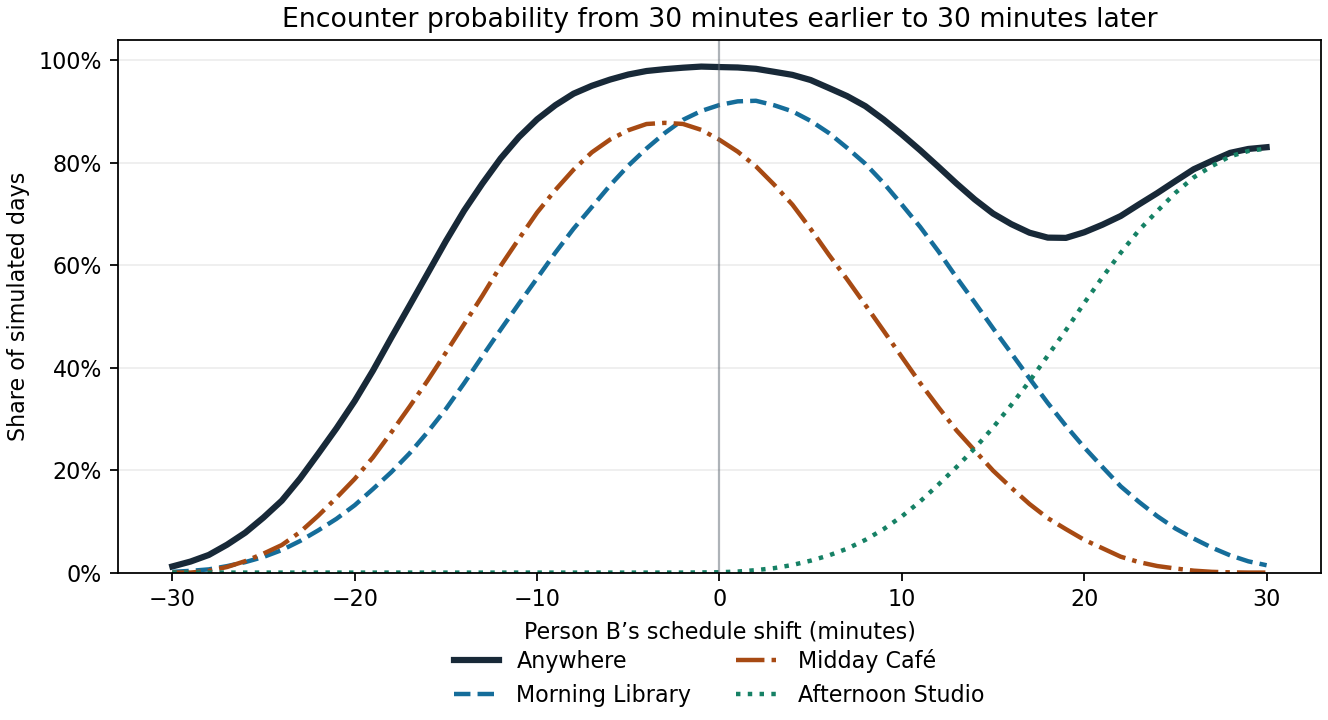

The highest simulated rate in the sweep was 98.81% at a -1-minute shift.
At −30 minutes the overall rate was 1.20%, and at +30 minutes it was 83.06%.


In [11]:
sweep_rates = sweep_counts / TRIALS
fig = Figure(figsize=(8.3, 4.5), layout="constrained")
ax = fig.subplots()
ax.plot(SWEEP_SHIFTS, sweep_rates[0], color="#182938", linewidth=2.8, label="Anywhere")
for row, ((label, _, _, _), color, style) in enumerate(
    zip(SWEEP_SERIES, ["#156d9a", "#a74a13", "#168165"], ["--", "-.", ":"]), start=1
):
    ax.plot(SWEEP_SHIFTS, sweep_rates[row], color=color, linestyle=style, linewidth=2, label=label)
ax.axvline(0, color="#5e6872", linewidth=1, alpha=0.5)
ax.set(
    title="Encounter probability from 30 minutes earlier to 30 minutes later",
    xlabel="Person B’s schedule shift (minutes)",
    ylabel="Share of simulated days",
    xticks=np.arange(-30, 31, 10),
    ylim=(0, 1.04),
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.22)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.29), ncol=2, frameon=False)
sweep_png = BytesIO()
fig.savefig(sweep_png, format="png", dpi=160)
display(Image(data=sweep_png.getvalue()))

best_sweep = int(np.argmax(sweep_rates[0]))
print(f"The highest simulated rate in the sweep was {sweep_rates[0, best_sweep]:.2%} "
      f"at a {SWEEP_SHIFTS[best_sweep]:+d}-minute shift.")
print(f"At −30 minutes the overall rate was {sweep_rates[0, 0]:.2%}, "
      f"and at +30 minutes it was {sweep_rates[0, -1]:.2%}.")
